# Aggregated Daily Sentiment and Short-Term Crypto Returns

Working model for the PBL-1 project (DSE 2170). Question: does daily aggregated sentiment
help predict BTC and ETH returns over the next 1 to 3 days, beyond momentum and volatility,
and does that depend on market conditions?

**Pipeline:** data → features → lead/lag check → HAC Granger tests (both directions) →
predictive regressions → walk-forward forecasting models → GARCH-X → regime analysis.

Set `DATA_MODE` below:

| Mode | Sentiment source | Price source | Keys needed |
|---|---|---|---|
| `"lunarcrush"` | LunarCrush social sentiment, posts, contributors, plus Fear & Greed | LunarCrush | `LUNARCRUSH_API_KEY` (CMC key optional) |
| `"cmc"` | CMC Fear & Greed | CMC | `CMC_API_KEY` (about 1 year of history on free plan) |
| `"free"` | alternative.me Fear & Greed | Binance public API | none |
| `"sample"` | synthetic, for testing only | synthetic | none |

In [1]:
# ---------------- settings ----------------
DATA_MODE = "sample"          # "lunarcrush" | "cmc" | "free" | "sample"
COINS     = ["BTC", "ETH"]
START     = "2020-01-01"
REFRESH   = False             # True = re-download instead of using cached CSVs in data/

In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import data_sources as ds, analysis as an, plots as pl

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
if DATA_MODE == "sample":
    print("SAMPLE MODE: synthetic data. Use it to check the code runs; the numbers mean nothing.")

SAMPLE MODE: synthetic data. Use it to check the code runs; the numbers mean nothing.


## 1. Load data

In [3]:
raw = {}
for coin in COINS:
    raw[coin] = ds.load_dataset(coin, mode=DATA_MODE, start=START, refresh=REFRESH)
    d = raw[coin]
    print(f"{coin}: {d.index.min().date()} to {d.index.max().date()}, {len(d)} days, columns: {list(d.columns)}")
raw[COINS[0]].tail()

BTC: 2022-01-01 to 2025-10-31, 1400 days, columns: ['open', 'close', 'high', 'low', 'volume_24h', 'sentiment', 'posts_active', 'contributors_active', 'interactions', 'fng']
ETH: 2022-01-01 to 2025-10-31, 1400 days, columns: ['open', 'close', 'high', 'low', 'volume_24h', 'sentiment', 'posts_active', 'contributors_active', 'interactions', 'fng']


,open,close,high,low,volume_24h,sentiment,posts_active,contributors_active,interactions,fng
date,,,,,,,,,,
2025-10-27,33178.4971,32250.6538,32381.1133,32120.1942,1.3645e+09,75.9572,13645.0960,4548.3653,491958.5360,48.6405
2025-10-28,32250.6538,32839.2936,33008.3476,32670.2397,1.3804e+09,70.6089,13803.7661,4601.2554,542215.8346,48.5958
2025-10-29,32839.2936,32660.9201,32743.7862,32578.0539,1.0202e+09,73.1247,10201.8641,3400.6214,402225.4305,53.4531
2025-10-30,32660.9201,33203.5891,33577.3874,32829.7907,9.4175e+08,65.0595,9417.5166,3139.1722,541422.7345,51.0201
2025-10-31,33203.5891,32616.8344,34373.5058,30860.1629,1.3234e+09,71.8245,13233.6700,4411.2233,247788.4232,54.1397


### Data quality check
Missing days and gaps in the sentiment columns. Prices are forward-filled across gaps;
sentiment is left missing (those days drop out of the models rather than being invented).

In [4]:
qc = pd.DataFrame({coin: d.isna().mean().mul(100).round(2) for coin, d in raw.items()})
qc.columns = [f"{c} % missing" for c in qc.columns]
qc

,BTC % missing,ETH % missing
open,0.0,0.0
close,0.0,0.0
high,0.0,0.0
low,0.0,0.0
volume_24h,0.0,0.0
sentiment,0.0,0.0
posts_active,0.0,0.0
contributors_active,0.0,0.0
interactions,0.0,0.0
fng,0.0,0.0


## 2. Features

- **Targets:** `fwd_h` = log return from today's close to the close h days ahead (h = 1, 2, 3).
- **Controls:** today's return `ret_1`, 5-day momentum `mom_5`, 20-day close-to-close vol `vol_cc`,
  20-day Parkinson range vol `vol_pk`.
- **Sentiment:** all converted to 90-day *backward-looking* z-scores so they are comparable and use no future data.
  - `sent_z`: share of positive posts (LunarCrush)
  - `sent_users_z`, `sent_posts_z`: mood weighted by number of active contributors / posts
  - `fng_z`: Fear & Greed index; `d_*`: day-over-day change
  - `attn_z`: attention (post volume, or trading volume if no social data)
  - **`score`**: the combined daily score, the average of the level z-scores, re-standardised

In [5]:
feat, SENT = {}, {}
for coin in COINS:
    feat[coin], SENT[coin] = an.build_features(raw[coin])
print("Sentiment features:", SENT[COINS[0]])
feat[COINS[0]][["close", "ret_1", "fwd_1", "mom_5", "vol_cc"] + SENT[COINS[0]]].dropna().describe().T

Sentiment features: ['score', 'sent_z', 'sent_users_z', 'sent_posts_z', 'd_sent_z', 'fng_z', 'd_fng_z', 'attn_z']


,count,mean,std,min,25%,50%,75%,max
close,1341.0,2.7683e+04,9418.9398,12967.6541,19827.9226,2.7691e+04,33348.2917,67592.0052
ret_1,1341.0,1.8208e-05,0.0312,-0.1580,-0.0170,-5.2639e-05,0.0166,0.1534
fwd_1,1341.0,2.9192e-05,0.0312,-0.1580,-0.0170,-5.2639e-05,0.0166,0.1534
mom_5,1341.0,-1.0710e-05,0.0753,-0.3503,-0.0415,3.2503e-04,0.0389,0.3798
vol_cc,1341.0,2.8831e-02,0.0110,0.0107,0.0218,2.6604e-02,0.0331,0.0900
score,1341.0,1.2213e-02,1.0389,-3.6709,-0.6562,2.7388e-02,0.6887,3.5491
sent_z,1341.0,3.0148e-03,1.0163,-3.3877,-0.6878,1.4530e-02,0.6458,3.5352
sent_users_z,1341.0,3.3975e-03,1.0145,-3.4216,-0.6701,-2.8826e-03,0.6490,3.8543
sent_posts_z,1341.0,3.3198e-03,1.0147,-3.4222,-0.6706,1.5960e-03,0.6531,3.8231
d_sent_z,1341.0,-1.0365e-04,1.0680,-3.7026,-0.7464,-1.4969e-02,0.7251,4.2061


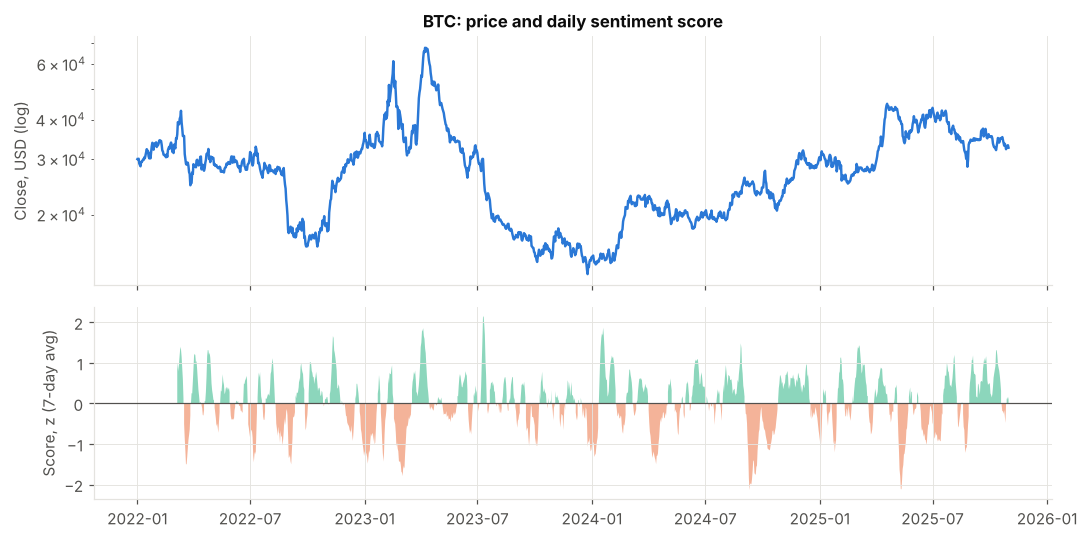

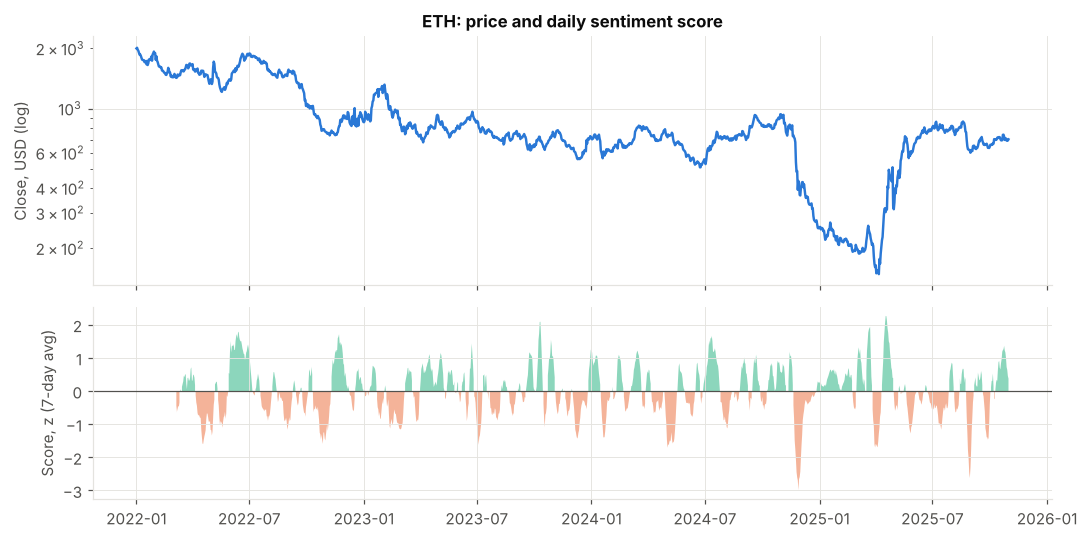

In [6]:
for coin in COINS:
    pl.price_and_score(feat[coin], coin); plt.show()

## 3. Does sentiment lead or follow price?

Bars on the left (orange) show how today's score relates to *past* returns; bars on the right
(blue) show how it relates to *future* returns. Tall left bars and flat right bars mean mood
mostly reacts to price.

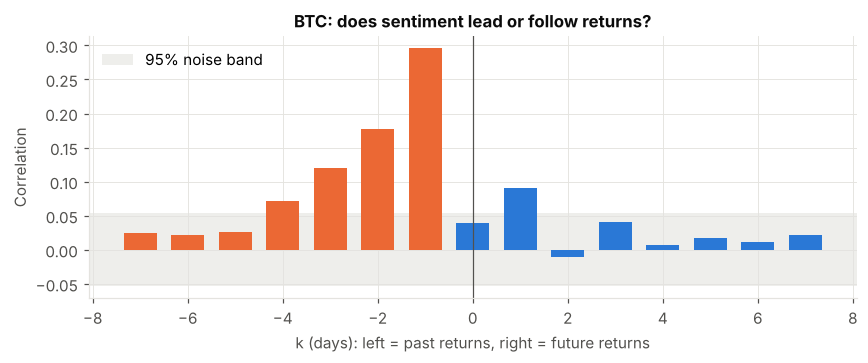

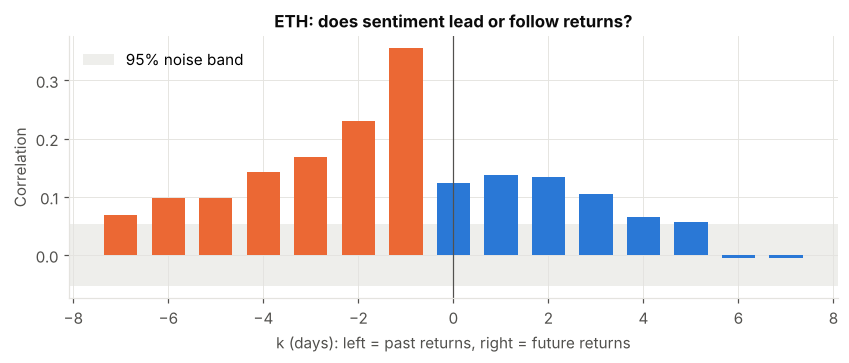

In [7]:
for coin in COINS:
    pl.lead_lag(feat[coin], coin); plt.show()

## 4. Granger causality with HAC errors (Objective 3.2.1)

For each direction we regress the effect on its own lags, lags of the cause, and lagged
momentum/volatility, then Wald-test that the cause's lags are jointly zero using Newey-West
standard errors. Small p-value = the cause adds predictive information.

In [8]:
granger = pd.concat({coin: an.granger_table(feat[coin], "score") for coin in COINS})
granger

direction  lags         F     p_value  sum_coef     n
BTC 0  score -> returns     1    5.2837  2.1525e-02    0.0022  1341
    1  returns -> score     1  128.2650  9.8215e-30    9.1676  1341
    2  score -> returns     2   12.5742  1.8602e-03    0.0007  1340
    3  returns -> score     2  128.0476  1.5661e-28   10.2872  1340
    4  score -> returns     3   14.4054  2.4022e-03    0.0011  1339
    5  returns -> score     3  130.5582  4.0999e-28    9.6581  1339
ETH 0  score -> returns     1   16.1512  5.8482e-05    0.0041  1341
    1  returns -> score     1  158.5682  2.3254e-36    8.3327  1341
    2  score -> returns     2   20.8738  2.9330e-05    0.0053  1340
    3  returns -> score     2  172.3820  3.6959e-38    9.4926  1340
    4  score -> returns     3   21.3298  8.9910e-05    0.0057  1339
    5  returns -> score     3  163.9226  2.6095e-35    9.3055  1339

## 5. Predictive regressions by horizon

`fwd_h ~ feature + controls`, HAC errors with lag ≥ h (overlapping returns).
`coef_bp` = extra return in basis points over the next h days for a +1 z move in the feature.

In [9]:
reg = {coin: an.regression_table(feat[coin], SENT[coin]) for coin in COINS}
pd.concat(reg).query("feature == 'score'")

feature  h   coef_bp  t_stat     p_value      r2     n
BTC 0   score  1   21.5904  2.2730  2.3024e-02  0.0117  1341
    1   score  2   10.4986  0.6766  4.9867e-01  0.0140  1340
    2   score  3   19.6704  0.8729  3.8272e-01  0.0184  1339
ETH 0   score  1   41.6676  4.0483  5.1599e-05  0.0277  1341
    1   score  2   78.4620  4.3052  1.6684e-05  0.0575  1340
    2   score  3  112.7498  4.5816  4.6148e-06  0.0695  1339

In [10]:
# all sentiment variants, next-day horizon
pd.concat({c: r.query("h == 1").set_index("feature")[["coef_bp", "t_stat", "p_value"]]
           for c, r in reg.items()}, axis=1)

BTC                      ETH                    
              coef_bp  t_stat p_value  coef_bp  t_stat     p_value
feature                                                           
score         21.5904  2.2730  0.0230  41.6676  4.0483  5.1599e-05
sent_z        26.5026  2.9050  0.0037  41.9463  3.3139  9.2003e-04
sent_users_z  26.6288  2.8437  0.0045  40.6988  3.2097  1.3288e-03
sent_posts_z  26.6405  2.8527  0.0043  40.8752  3.2238  1.2651e-03
d_sent_z      30.5868  3.4099  0.0006   1.9239  0.1542  8.7748e-01
fng_z          6.8664  0.7696  0.4416   6.5622  0.5573  5.7732e-01
d_fng_z        5.2415  0.7734  0.4393  -7.7421 -0.7477  4.5464e-01
attn_z        -4.3215 -0.5125  0.6083  -9.4012 -0.7916  4.2859e-01

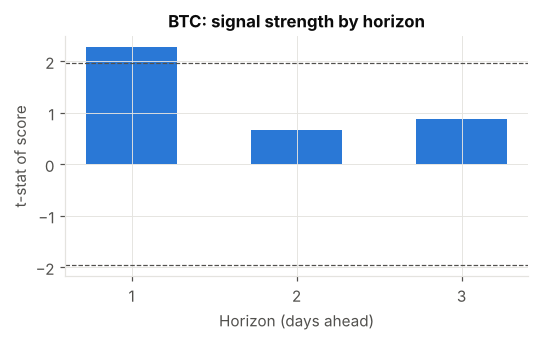

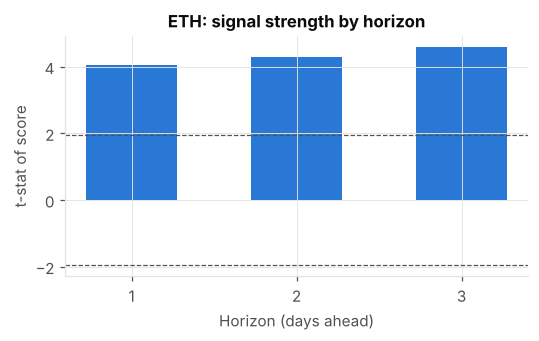

In [11]:
for coin in COINS:
    pl.decay(reg[coin], coin); plt.show()

## 6. Out-of-sample forecasting (Objective 3.2.2)

Expanding-window walk-forward: the first year is training only, models refit every 30 days,
and each refit trains only on rows whose h-day-ahead return was already known.

- **R2_OS_%**: out-of-sample R² against the historical-mean forecast. Positive = beats it.
  For daily crypto returns, anything above about 0.5% is meaningful.
- **hit_rate_%**: share of days the forecast got the direction right.
- **strategy_sharpe_gross**: annualised Sharpe of going long/short on the forecast sign, no costs.
- **CW_p_vs_controls**: Clark-West test p-value. Does adding sentiment beat the same model
  with only price controls? This is the key column.

In [12]:
forecasts, scores = {}, {}
for coin in COINS:
    for h in an.HORIZONS:
        fc = an.walk_forward(feat[coin], SENT[coin], h=h)
        forecasts[(coin, h)] = fc
        scores[(coin, h)] = an.score_forecasts(fc, h)
scores_df = pd.concat(scores, names=["coin", "h"])
scores_df

R2_OS_%  hit_rate_%  strategy_sharpe_gross  CW_p_vs_controls
coin h model                                                                                        
BTC  1 Ridge (controls only)            -0.0757     49.2828                -1.1109               NaN
       Ridge (+ sentiment)               0.6180     53.1762                 1.2772            0.0032
       Lasso (+ sentiment)              -0.0284     51.9467                 1.0483            0.0130
       Gradient boosting (+ sentiment)  -4.4343     49.7951                -0.0505            0.2274
       Historical mean                   0.0000     47.5410                -1.3208               NaN
     2 Ridge (controls only)             0.0971     50.1538                -0.0830               NaN
       Ridge (+ sentiment)              -2.8716     48.7179                 0.5499            0.8131
       Lasso (+ sentiment)              -0.4860     46.6667                -0.8362            0.3220
       Gradient boosting (+ sentiment)  -5.7168     47.4872                 0.1020            0.5437
       Historical mean                   0.0000     47.7949                -0.5286               NaN
     3 Ridge (controls only)             0.1324     50.4107                 0.3409               NaN
       Ridge (+ sentiment)              -2.0870     49.1786                 0.2466            0.2414
       Lasso (+ sentiment)              -0.5412     46.7146                -0.5587            0.2025
       Gradient boosting (+ sentiment)  -8.3073     45.5852                -0.4564            0.7350
       Historical mean                   0.0000     46.6119                -0.5103               NaN
ETH  1 Ridge (controls only)            -0.5246     51.1270                 0.1640               NaN
       Ridge (+ sentiment)               0.6672     53.7910                 1.5468            0.0075
       Lasso (+ sentiment)              -0.0907     52.3566                 0.6896            0.0833
       Gradient boosting (+ sentiment)  -1.9419     51.3320                 0.3896            0.2360
       Historical mean                   0.0000     50.6148                 0.0867               NaN
     2 Ridge (controls only)             0.1030     50.8718                 0.3776               NaN
       Ridge (+ sentiment)               1.8943     54.0513                 0.9727            0.0125
       Lasso (+ sentiment)               2.1293     54.4615                 1.3026            0.0011
       Gradient boosting (+ sentiment)  -3.3216     48.9231                -0.4834            0.4737
       Historical mean                   0.0000     49.6410                 0.0814               NaN
     3 Ridge (controls only)            -1.0098     51.1294                 0.4519               NaN
       Ridge (+ sentiment)               0.9418     52.5667                 0.7050            0.0072
       Lasso (+ sentiment)               2.1761     54.5175                 1.8618            0.0015
       Gradient boosting (+ sentiment)   0.2006     50.8214                 1.3720            0.0146
       Historical mean                   0.0000     49.6920                 0.0888               NaN

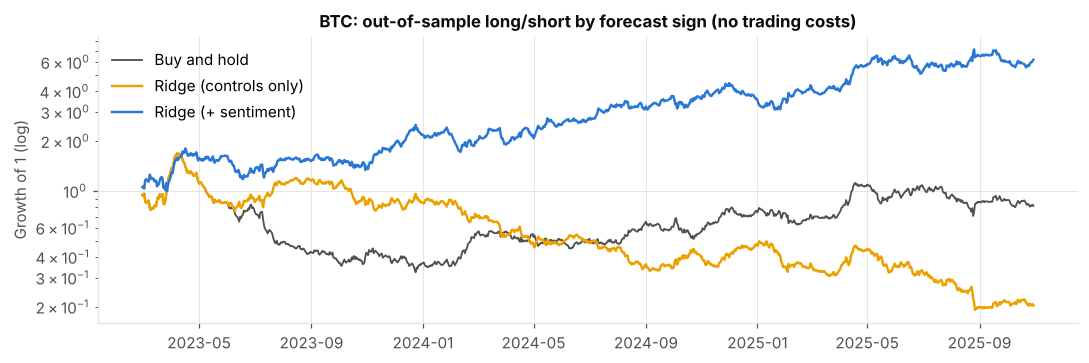

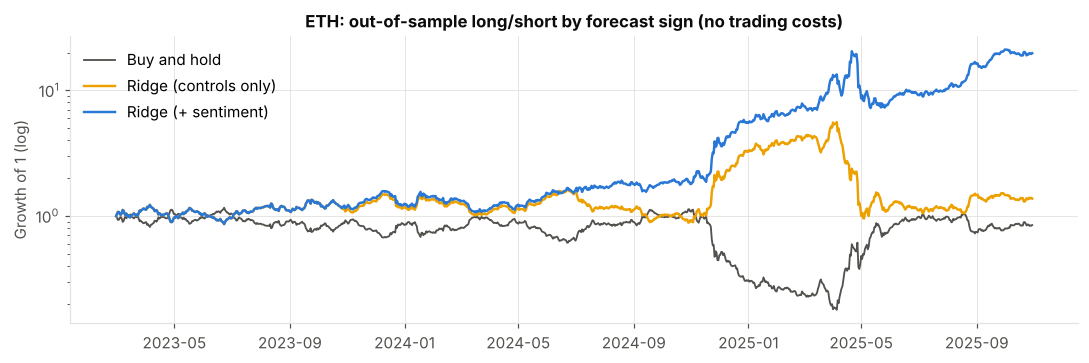

In [13]:
for coin in COINS:
    pl.cumulative_strategy(forecasts[(coin, 1)], coin); plt.show()

## 7. GARCH-X

AR-GARCH(1,1) with Student-t errors and yesterday's score in the mean equation. This checks the
sentiment effect after allowing for volatility clustering and fat tails. (The `arch` library only
supports extra regressors in the mean, not the variance.)

In [14]:
pd.concat({coin: an.garch_x(feat[coin]) for coin in COINS}, axis=1)

BTC                          ETH                     
            coef   t_stat     p_value    coef   t_stat     p_value
Const    -0.0198  -0.2776  7.8129e-01 -0.0816  -1.2484  2.1190e-01
score_L1  0.1504   2.0379  4.1560e-02  0.3300   4.8819  1.0505e-06
ret_L1    0.9238   0.3238  7.4608e-01  4.0793   1.5370  1.2430e-01
omega     0.5810   2.7551  5.8674e-03  0.3816   3.4410  5.7948e-04
alpha[1]  0.1036   3.6301  2.8336e-04  0.0994   5.2649  1.4025e-07
beta[1]   0.8350  19.6063  1.3669e-85  0.8665  42.6437  0.0000e+00
nu        6.4077   6.3534  2.1056e-10  4.6633   8.2886  1.1459e-16

## 8. Regime analysis (Objective 3.2.3)

Same next-day regression, run separately inside each market state:
- **Volatility:** above vs below the expanding median of 20-day vol (no look-ahead)
- **Markov state:** two-state Markov switching model on returns (calm vs turbulent), smoothed probabilities
- **Attention:** above vs below normal post volume (or trading volume)
- **Trend:** price above vs below its 50-day average

In [15]:
regime = {}
for coin in COINS:
    feat[coin]["p_high_vol"] = an.markov_regimes(feat[coin])
    regime[coin] = an.regime_table(feat[coin], "score", h=1)
pd.concat(regime)

regime      state  coef_bp  t_stat     p_value     n
BTC 0    Volatility       High  45.8233  2.4936  1.2646e-02   549
    1    Volatility        Low   6.1985  0.6117  5.4073e-01   792
    2  Markov state       Calm   5.7741  0.7629  4.4553e-01  1152
    3  Markov state  Turbulent  95.9275  1.9611  4.9862e-02   189
    4     Attention       High  37.0611  2.5792  9.9041e-03   660
    5     Attention        Low   3.1586  0.2847  7.7586e-01   681
    6         Trend       Down  19.8260  1.6586  9.7205e-02   709
    7         Trend         Up  22.6373  1.5433  1.2275e-01   632
ETH 0    Volatility       High  55.3807  3.2005  1.3721e-03   716
    1    Volatility        Low  25.8944  2.7448  6.0539e-03   625
    2  Markov state       Calm  30.2447  4.2514  2.1248e-05  1135
    3  Markov state  Turbulent  94.6120  1.7396  8.1935e-02   206
    4     Attention       High  45.8939  2.8753  4.0367e-03   646
    5     Attention        Low  37.4885  3.4617  5.3670e-04   695
    6         Trend       Down  43.6135  3.8948  9.8277e-05   751
    7         Trend         Up  40.2531  2.0697  3.8477e-02   590

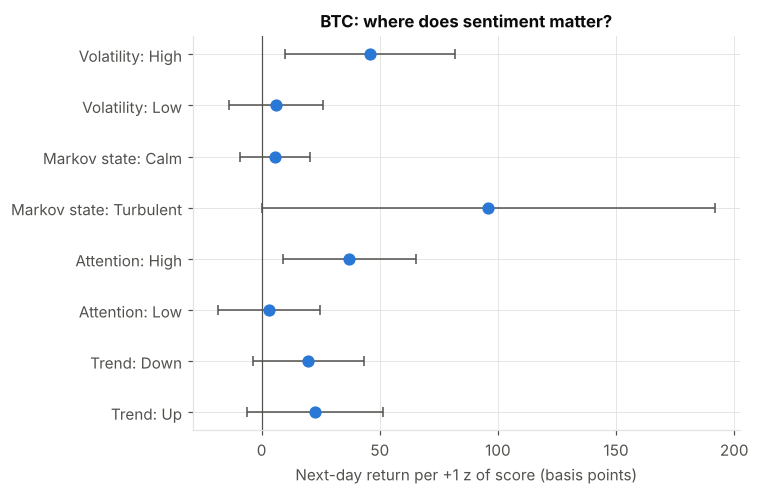

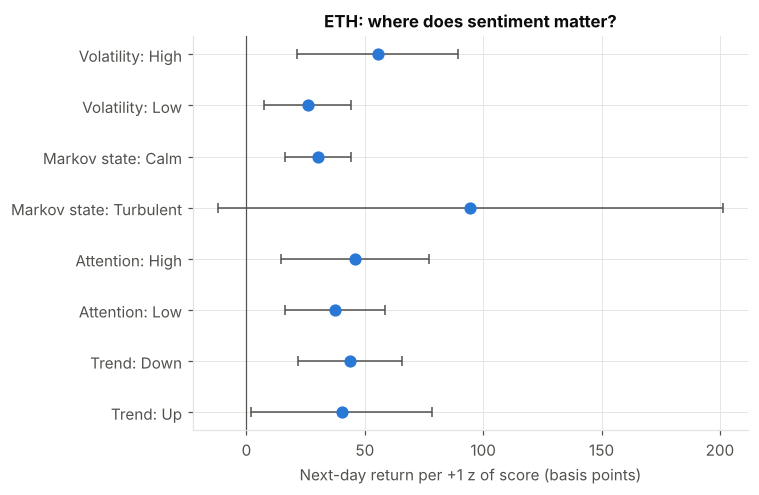

In [16]:
for coin in COINS:
    pl.regimes(regime[coin], coin); plt.show()

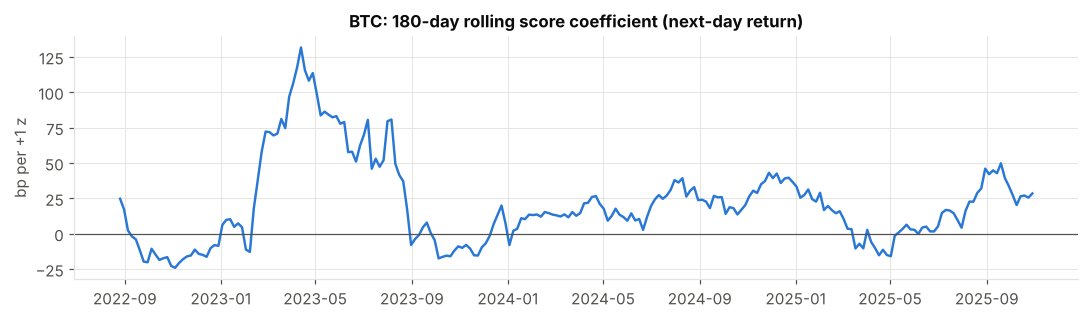

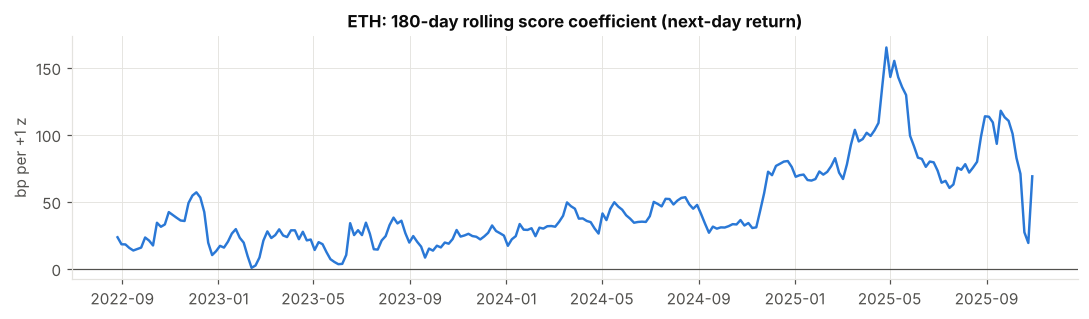

In [17]:
for coin in COINS:
    pl.rolling(an.rolling_coef(feat[coin], "score", h=1), coin); plt.show()

## 9. Summary

In [18]:
rows = []
for coin in COINS:
    g = granger.loc[coin]
    s1 = scores[(coin, 1)].loc["Ridge (+ sentiment)"]
    r = reg[coin].query("feature == 'score'").set_index("h")
    rv = regime[coin].set_index(["regime", "state"])
    rows.append({
        "coin": coin,
        "score->returns p (lag 1)": g.query("direction == 'score -> returns' and lags == 1")["p_value"].iat[0],
        "returns->score p (lag 1)": g.query("direction == 'returns -> score' and lags == 1")["p_value"].iat[0],
        "t-stat h=1": r.loc[1, "t_stat"], "t-stat h=3": r.loc[3, "t_stat"],
        "R2_OS % (Ridge+sent, h=1)": s1["R2_OS_%"],
        "CW p vs controls (h=1)": s1["CW_p_vs_controls"],
        "coef bp, high vol": rv.loc[("Volatility", "High"), "coef_bp"],
        "coef bp, low vol": rv.loc[("Volatility", "Low"), "coef_bp"],
    })
summary = pd.DataFrame(rows).set_index("coin")
summary.round(4)

,score->returns p (lag 1),returns->score p (lag 1),t-stat h=1,t-stat h=3,"R2_OS % (Ridge+sent, h=1)",CW p vs controls (h=1),"coef bp, high vol","coef bp, low vol"
coin,,,,,,,,
BTC,0.0215,0.0,2.2730,0.8729,0.6180,0.0032,45.8233,6.1985
ETH,0.0001,0.0,4.0483,4.5816,0.6672,0.0075,55.3807,25.8944


**Reading the summary against the report's expected outcomes (section 4.6):**
1. *Next-day predictability:* look at `score->returns p`, `t-stat h=1`, and `CW p vs controls`.
2. *Fades after 2 to 3 days:* compare `t-stat h=1` with `t-stat h=3`.
3. *Stronger in volatile markets:* compare the high-vol and low-vol coefficients.
4. *Does mood mostly follow price?* A tiny `returns->score p` alongside a weak `score->returns p` says yes.

In [19]:
import os; os.makedirs("results", exist_ok=True)
summary.to_csv(f"results/summary_{DATA_MODE}.csv")
scores_df.to_csv(f"results/forecast_scores_{DATA_MODE}.csv")
granger.to_csv(f"results/granger_{DATA_MODE}.csv")
pd.concat(regime).to_csv(f"results/regimes_{DATA_MODE}.csv")
print("Saved tables to results/")

Saved tables to results/
